# Urban Air Quality Mining — Thực thi & Đánh giá các Mô hình đã Huấn luyện
> **Bài tập lớn môn Khai phá dữ liệu (CO3029)**  
> **Nhiệm vụ:** Hồi quy nồng độ bụi mịn PM2.5 ($t+1$) & Phân loại 6 cấp độ ô nhiễm theo QCVN/QĐ 1459/QĐ-TCMT  
> **Trạm đo:** CMT8, TP. Hồ Chí Minh (OpenAQ ID: 3276359)  

Trình tự mô hình hóa:
1. Nạp tập dữ liệu thực nghiệm đã chuẩn bị sẵn (`data/processed/openaq_cmt8_model_ready.csv`).
2. Nạp toàn bộ các mô hình đã được huấn luyện và lưu tại `artifacts/models/` (Ridge, Random Forest, XGBoost, LSTM, RF Classifier, XGB Classifier).
3. Chạy inference đồng loạt trên tập Test.
4. Tổng hợp, so sánh đa chỉ số khách quan (RMSE, MAE, R², MAPE, Accuracy, Macro-F1, Lift, Confusion Matrix).
5. Xây dựng hàm dự báo nhanh cho 1 mẫu dữ liệu mới theo thời gian thực.


In [1]:
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import torch
import torch.nn as nn
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score,
    accuracy_score, f1_score, confusion_matrix
)
import xgboost as xgb

# Cấu hình đường dẫn thư mục gốc dự án
PROJECT_ROOT = Path('.').resolve().parent if Path('.').resolve().name == 'notebooks' else Path('.').resolve()
sys.path.insert(0, str(PROJECT_ROOT))

from src.air_quality_mining.models import (
    LSTMRegressor, pm25_series_to_aqi, pm25_to_aqi_category,
    compute_regression_metrics, compute_classification_metrics,
    create_sliding_sequences, compute_lift_score,
    AQI_CATEGORY_NAMES, AQI_CATEGORY_VI
)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print('Thư viện đã được tải thành công! PROJECT_ROOT:', PROJECT_ROOT)


Thư viện đã được tải thành công! PROJECT_ROOT: C:\BPH\ProjectGithub\urban-air-quality-mining


## 1. Nạp tập dữ liệu thực nghiệm
Đọc tập dữ liệu đã qua tiền xử lý, kiểm tra kích thước và cấu trúc các tập Train, Validation, Test.


In [2]:
data_path = PROJECT_ROOT / 'data' / 'processed' / 'openaq_cmt8_model_ready.csv'
df = pd.read_csv(data_path)

features = [
    'pm2_5_ug_m3_input_causal',
    'pm2_5_rolling24h_mean',
    'temperature_c_input_causal',
    'hour_sin',
    'hour_cos',
    'month_sin',
    'month_cos',
]
target = 'target_pm2_5_next_hour'

train_df = df[df['split'] == 'train'].reset_index(drop=True)
val_df = df[df['split'] == 'validation'].reset_index(drop=True)
test_df = df[df['split'] == 'test'].reset_index(drop=True)

X_test = test_df[features]
y_test = test_df[target].values

print(f'Tổng số mẫu: {len(df)}')
print(f' - Tập Train: {len(train_df)} mẫu')
print(f' - Tập Validation: {len(val_df)} mẫu')
print(f' - Tập Test: {len(test_df)} mẫu')
test_df.head(5)


Tổng số mẫu: 14523
 - Tập Train: 9961 mẫu
 - Tập Validation: 2278 mẫu
 - Tập Test: 2284 mẫu


,pm2_5_ug_m3_input_causal,pm2_5_rolling24h_mean,temperature_c_input_causal,hour_sin,hour_cos,month_sin,month_cos,target_pm2_5_next_hour,split
0,23.0,30.804167,30.8,-0.707107,-7.071068e-01,-0.5,-0.866025,17.7,test
1,17.7,30.912500,31.1,-0.866025,-5.000000e-01,-0.5,-0.866025,16.8,test
2,16.8,30.750000,31.3,-0.965926,-2.588190e-01,-0.5,-0.866025,18.8,test
3,18.8,30.475000,30.1,-1.000000,-1.836970e-16,-0.5,-0.866025,25.6,test
4,25.6,30.600000,29.7,-0.965926,2.588190e-01,-0.5,-0.866025,27.2,test


## 2. Nạp toàn bộ các Mô hình & Scalers đã huấn luyện từ `artifacts/models/`


In [3]:
models_dir = PROJECT_ROOT / 'artifacts' / 'models'

# 1. Nạp Scalers
scaler_x = joblib.load(models_dir / 'scaler_x.joblib')
scaler_y = joblib.load(models_dir / 'scaler_y.joblib')

# 2. Nạp Mô hình Hồi quy Machine Learning
ridge = joblib.load(models_dir / 'ridge_baseline.joblib')
rf_reg = joblib.load(models_dir / 'rf_regressor.joblib')

xgb_reg = xgb.XGBRegressor()
xgb_reg.load_model(str(models_dir / 'xgb_regressor.json'))

# 3. Nạp Mô hình Deep Learning LSTM (PyTorch)
with open(models_dir / 'lstm_config.json', 'r', encoding='utf-8') as f:
    lstm_cfg = json.load(f)

lstm_reg = LSTMRegressor(
    input_dim=lstm_cfg['input_dim'],
    hidden_dim=lstm_cfg['hidden_dim'],
    num_layers=lstm_cfg['num_layers'],
    dropout=lstm_cfg['dropout']
)
lstm_reg.load_state_dict(torch.load(models_dir / 'lstm_regressor.pt', weights_only=True))
lstm_reg.eval()

# 4. Nạp Mô hình Phân loại Đa lớp Trực tiếp
rf_clf = joblib.load(models_dir / 'rf_classifier.joblib')
xgb_clf = xgb.XGBClassifier()
xgb_clf.load_model(str(models_dir / 'xgb_classifier.json'))

print('Tất cả các mô hình và bộ chuẩn hóa đã được nạp thành công!')


Tất cả các mô hình và bộ chuẩn hóa đã được nạp thành công!


## 3. Thực thi Dự báo Hồi quy trên Tập Test
Chúng ta tính toán dự báo nồng độ PM2.5 ở giờ kế tiếp từ tất cả các mô hình:
- **Persistence Baseline:** $\hat{y}_{t+1} = y_t$
- **Ridge Regression:** Hồi quy tuyến tính hiệu chuẩn L2
- **Random Forest Regressor:** Rừng cây ngẫu nhiên
- **XGBoost Regressor:** Tối ưu gradient bậc 2
- **LSTM Regressor:** Mạng nơ-ron hồi quy chuỗi thời gian


In [4]:
# 1. Persistence Baseline
y_pred_persist = test_df['pm2_5_ug_m3_input_causal'].values

# 2. Ridge Baseline
y_pred_ridge = ridge.predict(X_test)

# 3. Random Forest Regressor
y_pred_rf = rf_reg.predict(X_test)

# 4. XGBoost Regressor
y_pred_xgb = xgb_reg.predict(X_test)

# 5. LSTM Regressor (chuỗi trượt seq_len)
seq_len = lstm_cfg['seq_len']
X_te_sc = scaler_x.transform(X_test)
X_te_seq, _ = create_sliding_sequences(X_te_sc, np.zeros(len(X_te_sc)), seq_len=seq_len)

with torch.no_grad():
    lstm_out = lstm_reg(torch.tensor(X_te_seq, dtype=torch.float32)).numpy()
y_pred_lstm = scaler_y.inverse_transform(lstm_out.reshape(-1, 1)).flatten()

# Căn chỉnh nhãn mục tiêu cho LSTM do bị mất seq_len mẫu đầu
# Sửa lỗi căn chỉnh t+1: cửa sổ seq_len có nhãn t+1 tại hàng seq_len-1
y_test_lstm = y_test[seq_len - 1 : len(y_test) - 1]

# Đóng gói kết quả dự báo
reg_predictions = {
    'Persistence Baseline': (y_pred_persist, y_test),
    'Ridge Baseline': (y_pred_ridge, y_test),
    'Random Forest Regressor': (y_pred_rf, y_test),
    'XGBoost Regressor': (y_pred_xgb, y_test),
    'LSTM Regressor': (y_pred_lstm, y_test_lstm),
}
print('Đã hoàn tất dự báo hồi quy cho toàn bộ 5 mô hình trên tập Test!')


Đã hoàn tất dự báo hồi quy cho toàn bộ 5 mô hình trên tập Test!


### Bảng tổng hợp Đánh giá Hiệu năng Hồi quy (RMSE, MAE, R², MAPE)


In [5]:
reg_summary = []
for name, (pred, true) in reg_predictions.items():
    metrics = compute_regression_metrics(true, pred)
    reg_summary.append({
        'Mô hình': name,
        'RMSE (µg/m³)': metrics['RMSE'],
        'MAE (µg/m³)': metrics['MAE'],
        'R² Score': metrics['R2'],
        'MAPE (%)': metrics['MAPE_pct']
    })

reg_summary_df = pd.DataFrame(reg_summary).sort_values(by='RMSE (µg/m³)')
reg_summary_df


,Mô hình,RMSE (µg/m³),MAE (µg/m³),R² Score,MAPE (%)
3,XGBoost Regressor,6.9911,4.9917,0.7916,20.91
4,LSTM Regressor,6.9959,4.9290,0.7917,19.86
1,Ridge Baseline,7.0666,5.0851,0.7871,21.26
2,Random Forest Regressor,7.0721,5.0176,0.7868,20.28
0,Persistence Baseline,7.3299,5.1429,0.7709,20.07


## 4. Phân loại Cấp độ AQI (6 Cấp theo QĐ 1459/QĐ-TCMT)
So sánh 2 hướng tiếp cận:
1. **Threshold Mapping:** Chuyển đổi nồng độ PM2.5 dự báo từ các mô hình hồi quy sang cấp độ ô nhiễm.
2. **Direct Multiclass Classification:** Dự báo trực tiếp nhãn cấp độ bằng Random Forest Classifier và XGBoost Classifier.


In [6]:
y_test_cat = pm25_series_to_aqi(y_test)
y_test_cat_lstm = pm25_series_to_aqi(y_test_lstm)

clf_summary = []

# 1. Majority Class Baseline
majority_cls = int(pd.Series(pm25_series_to_aqi(train_df[target])).mode()[0])
y_pred_maj = np.full_like(y_test_cat, majority_cls)
m_maj = compute_classification_metrics(y_test_cat, y_pred_maj)
clf_summary.append({'Mô hình': 'Majority Class Baseline', 'Tiếp cận': 'Baseline Luật', **m_maj})

# 2. Threshold Mapping từ các mô hình Hồi quy
for name, (pred, true) in reg_predictions.items():
    pred_cat = pm25_series_to_aqi(pred)
    true_cat = y_test_cat_lstm if name == 'LSTM Regressor' else y_test_cat
    m = compute_classification_metrics(true_cat, pred_cat)
    clf_summary.append({'Mô hình': f'{name} -> AQI', 'Tiếp cận': 'Threshold Mapping', **m})

# 3. Direct Classifiers
y_pred_rf_clf = rf_clf.predict(X_test)
m_rf_c = compute_classification_metrics(y_test_cat, y_pred_rf_clf)
clf_summary.append({'Mô hình': 'Random Forest Classifier (balanced)', 'Tiếp cận': 'Direct Multiclass', **m_rf_c})

y_pred_xgb_clf = xgb_clf.predict(X_test)
m_xgb_c = compute_classification_metrics(y_test_cat, y_pred_xgb_clf)
clf_summary.append({'Mô hình': 'XGBoost Classifier', 'Tiếp cận': 'Direct Multiclass', **m_xgb_c})

clf_summary_df = pd.DataFrame(clf_summary).sort_values(by='Accuracy', ascending=False)
clf_summary_df


,Mô hình,Tiếp cận,Accuracy,Macro_F1,Weighted_F1,AUC_ROC_macro
5,LSTM Regressor -> AQI,Threshold Mapping,0.8191,0.6714,0.8164,None
3,Random Forest Regressor -> AQI,Threshold Mapping,0.8104,0.6502,0.8083,None
4,XGBoost Regressor -> AQI,Threshold Mapping,0.8065,0.6668,0.8042,None
1,Persistence Baseline -> AQI,Threshold Mapping,0.8039,0.7286,0.8038,None
7,XGBoost Classifier,Direct Multiclass,0.8030,0.6556,0.8003,None
2,Ridge Baseline -> AQI,Threshold Mapping,0.8008,0.6978,0.7994,None
6,Random Forest Classifier (balanced),Direct Multiclass,0.7802,0.6452,0.7825,None
0,Majority Class Baseline,Baseline Luật,0.4742,0.1608,0.3050,None


### 4.2. Đánh giá Khả năng Cảnh báo Sớm Ô nhiễm (Ngưỡng PM2.5 ≥ 45 & ≥ 50 µg/m³)

Trong bài toán bảo vệ sức khỏe cộng đồng, **Recall (độ nhạy)** tại ngưỡng ô nhiễm cao quan trọng hơn RMSE tổng quát, vì bỏ sót một đợt ô nhiễm nguy hiểm (False Negative) có hệ quả sức khỏe nghiêm trọng hơn việc báo nhầm (False Positive). Dưới đây là bảng đánh giá đa chỉ số kèm khoảng tin cậy 95% Bootstrap.

In [7]:
from src.air_quality_mining.models import compute_threshold_detection_metrics

thr_summary = []
for name, (pred, true) in reg_predictions.items():
    res = compute_threshold_detection_metrics(true, pred, thresholds=[45.0, 50.0], n_bootstrap=1000)
    for r in res:
        thr_summary.append({
            'Mô hình': name,
            'Ngưỡng (µg/m³)': r['threshold_ug_m3'],
            'Số sự kiện': r['n_events'],
            'Recall': r['recall'],
            '95% CI Recall': f"[{r['recall_ci95_lo']:.3f}, {r['recall_ci95_hi']:.3f}]",
            'Precision': r['precision'],
            'F1-Score': r['f1'],
            'Tỷ lệ báo nhầm (FAR)': r['false_alarm_rate'],
        })

thr_summary_df = pd.DataFrame(thr_summary).sort_values(by=['Ngưỡng (µg/m³)', 'Recall'], ascending=[True, False])
thr_summary_df

,Mô hình,Ngưỡng (µg/m³),Số sự kiện,Recall,95% CI Recall,Precision,F1-Score,Tỷ lệ báo nhầm (FAR)
0,Persistence Baseline,45.0,320,0.7500,"[0.700, 0.797]",0.7500,0.7500,0.0407
4,Random Forest Regressor,45.0,320,0.7312,"[0.682, 0.778]",0.8041,0.7660,0.0290
2,Ridge Baseline,45.0,320,0.6813,"[0.629, 0.733]",0.8074,0.7390,0.0265
6,XGBoost Regressor,45.0,320,0.6813,"[0.628, 0.732]",0.8226,0.7453,0.0239
8,LSTM Regressor,45.0,320,0.6344,"[0.584, 0.685]",0.8320,0.7199,0.0209
1,Persistence Baseline,50.0,207,0.7440,"[0.680, 0.799]",0.7440,0.7440,0.0255
5,Random Forest Regressor,50.0,207,0.6618,"[0.595, 0.725]",0.8059,0.7268,0.0159
3,Ridge Baseline,50.0,207,0.6425,"[0.578, 0.704]",0.7917,0.7093,0.0169
9,LSTM Regressor,50.0,207,0.6377,"[0.571, 0.699]",0.8627,0.7333,0.0101
7,XGBoost Regressor,50.0,207,0.6329,"[0.567, 0.698]",0.8037,0.7081,0.0154


### 4.3. Phân tích Đóng góp Đặc trưng (Feature Ablation Study)

Kiểm tra thực nghiệm trên tập Validation khi loại bỏ đặc trưng chu kỳ tháng (`month_sin/cos`) và nhiệt độ để trả lời câu hỏi: các đặc trưng này có thực sự cải thiện chất lượng dự báo khi dữ liệu chưa đầy 2 năm?

In [8]:
ablation_path = PROJECT_ROOT / 'artifacts' / 'metrics' / 'feature_ablation.csv'
if ablation_path.exists():
    abl_df = pd.read_csv(ablation_path)
    display(abl_df)
else:
    print('Chưa có file feature_ablation.csv')


,features,n_features,model,RMSE,MAE,R2,MAPE_pct
0,Full (all 7 features),7,Ridge,6.0812,4.1847,0.6459,20.42
1,Full (all 7 features),7,RF,5.7770,3.9746,0.6804,19.26
2,No month_sin/cos,5,Ridge,6.1279,4.2533,0.6404,21.22
3,No month_sin/cos,5,RF,5.7796,3.9852,0.6801,19.35
4,No temperature,6,Ridge,6.1032,4.2020,0.6433,20.49
5,No temperature,6,RF,5.8913,3.9983,0.6677,19.38
6,No month + No temp,4,Ridge,6.1534,4.2783,0.6374,21.37
7,No month + No temp,4,RF,5.8952,4.0148,0.6672,19.48


## 5. Trực quan hóa Kết quả Thực nghiệm
### 5.1. So sánh Chuỗi thời gian Dự báo vs Thực tế (1 tuần đầu tập Test)


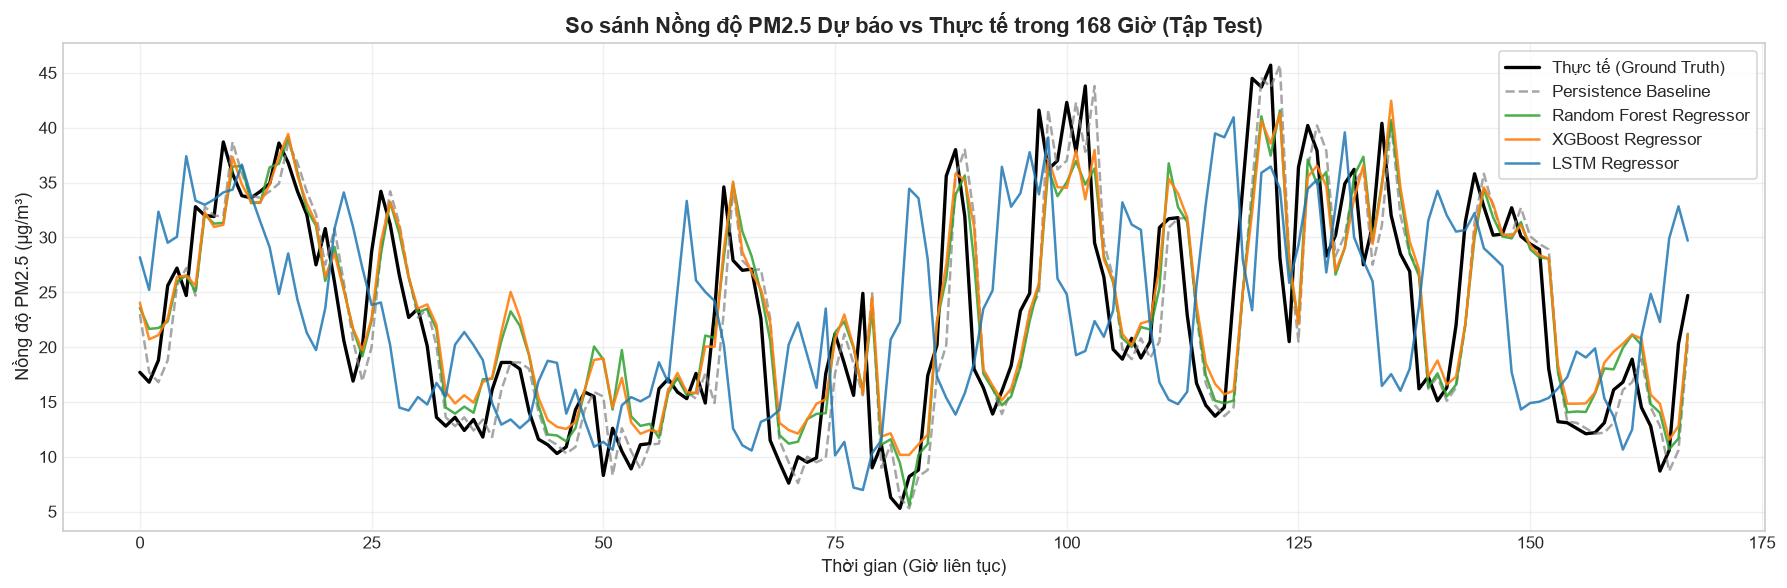

In [9]:
plt.figure(figsize=(15, 5), dpi=120)
window = 168  # 1 tuần (168 giờ)
plt.plot(y_test[:window], label='Thực tế (Ground Truth)', color='black', linewidth=2.0)
plt.plot(y_pred_persist[:window], label='Persistence Baseline', color='gray', linestyle='--', alpha=0.7)
plt.plot(y_pred_rf[:window], label='Random Forest Regressor', color='tab:green', alpha=0.85)
plt.plot(y_pred_xgb[:window], label='XGBoost Regressor', color='tab:orange', linewidth=1.5, alpha=0.9)
plt.plot(y_pred_lstm[:window], label='LSTM Regressor', color='tab:blue', alpha=0.85)

plt.title('So sánh Nồng độ PM2.5 Dự báo vs Thực tế trong 168 Giờ (Tập Test)', fontsize=13, fontweight='bold')
plt.xlabel('Thời gian (Giờ liên tục)', fontsize=11)
plt.ylabel('Nồng độ PM2.5 (µg/m³)', fontsize=11)
plt.grid(True, alpha=0.3)
plt.legend(frameon=True, loc='upper right')
plt.tight_layout()
plt.show()


### 5.2. Ma trận Nhầm lẫn (Confusion Matrix) trên 4 Cấp Ô nhiễm thực tế
*(Ghi chú: Cấp 'Rất xấu' và 'Nguy hại' không xuất hiện trong giai đoạn tập Test do tính chất mùa vụ)*


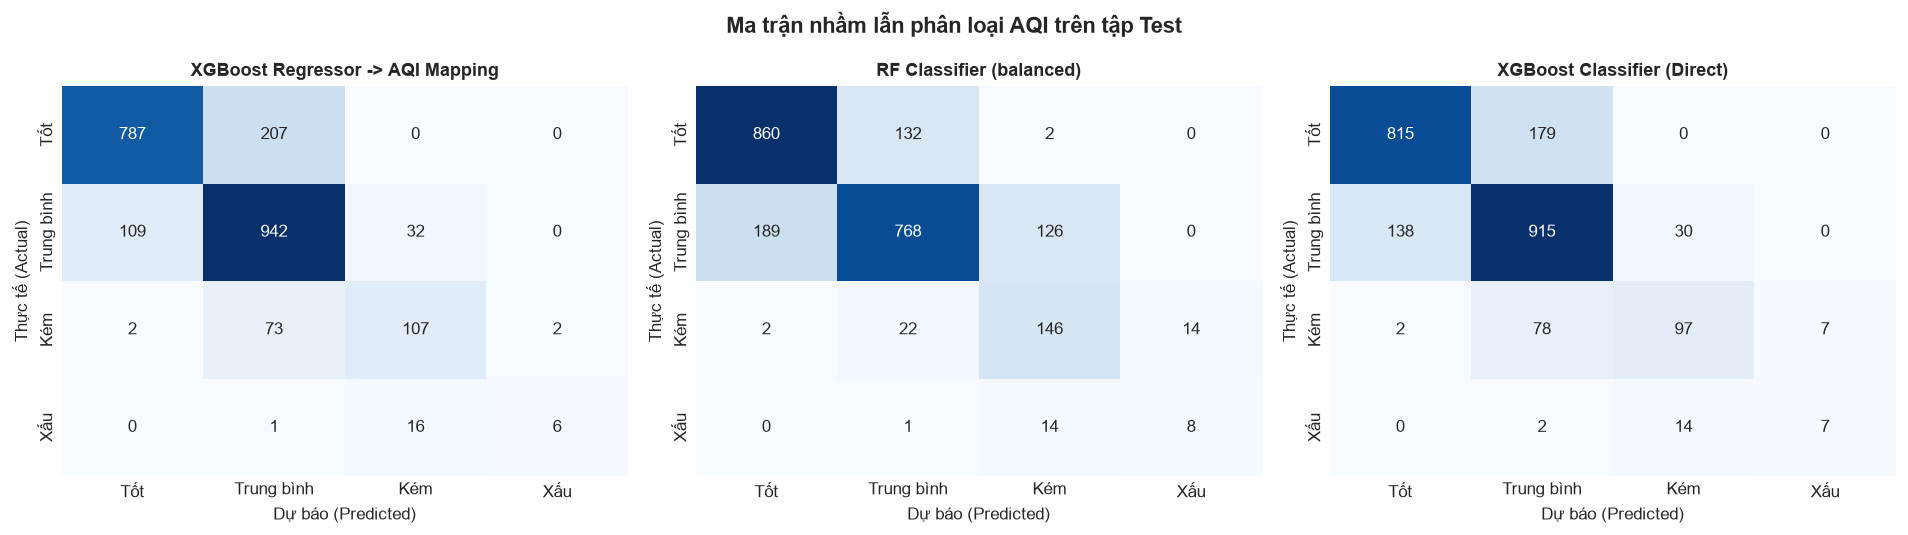

In [10]:
labels_4 = ['Tốt', 'Trung bình', 'Kém', 'Xấu']
cm_xgb_map = confusion_matrix(y_test_cat, pm25_series_to_aqi(y_pred_xgb), labels=[0, 1, 2, 3])
cm_rf_dir = confusion_matrix(y_test_cat, y_pred_rf_clf, labels=[0, 1, 2, 3])
cm_xgb_dir = confusion_matrix(y_test_cat, y_pred_xgb_clf, labels=[0, 1, 2, 3])

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), dpi=120)
cms = [cm_xgb_map, cm_rf_dir, cm_xgb_dir]
titles = [
    'XGBoost Regressor -> AQI Mapping',
    'RF Classifier (balanced)',
    'XGBoost Classifier (Direct)'
]

for ax, cm, title in zip(axes, cms, titles):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=labels_4, yticklabels=labels_4, cbar=False)
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_xlabel('Dự báo (Predicted)')
    ax.set_ylabel('Thực tế (Actual)')

plt.suptitle('Ma trận nhầm lẫn phân loại AQI trên tập Test', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


### 5.3. Biểu đồ Lift (Hệ số Cải thiện Cảnh báo Sớm Ô nhiễm Cao)


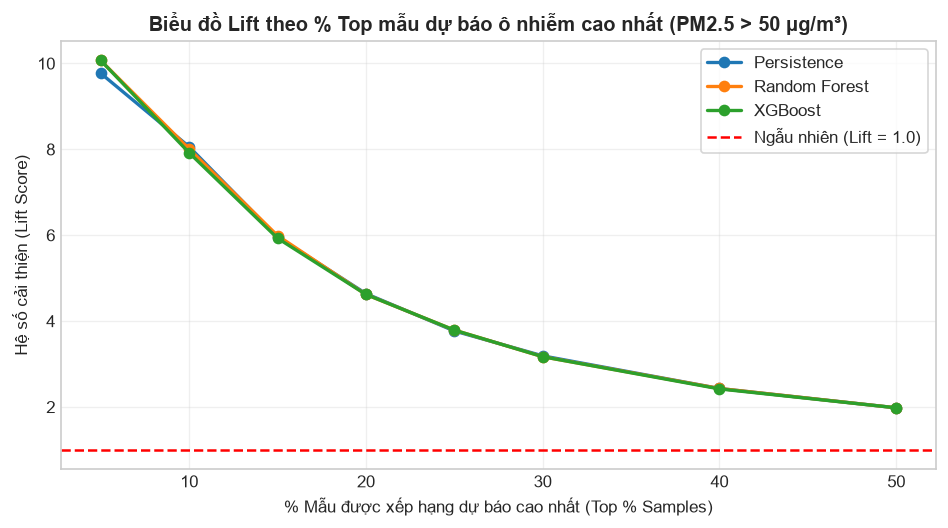

In [11]:
fractions = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]
plt.figure(figsize=(8, 4.5), dpi=120)

for m_name, pred in [('Persistence', y_pred_persist), ('Random Forest', y_pred_rf), ('XGBoost', y_pred_xgb)]:
    lifts = []
    for f in fractions:
        l = compute_lift_score(y_test, pred, high_threshold=50.0, top_fraction=f)
        lifts.append(l[f'lift_at_{int(f*100)}pct'])
    plt.plot([f*100 for f in fractions], lifts, marker='o', label=m_name, linewidth=2)

plt.axhline(1.0, color='red', linestyle='--', label='Ngẫu nhiên (Lift = 1.0)')
plt.title('Biểu đồ Lift theo % Top mẫu dự báo ô nhiễm cao nhất (PM2.5 > 50 µg/m³)', fontsize=12, fontweight='bold')
plt.xlabel('% Mẫu được xếp hạng dự báo cao nhất (Top % Samples)')
plt.ylabel('Hệ số cải thiện (Lift Score)')
plt.grid(True, alpha=0.3)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()


## 6. Hàm Tiện ích Dự báo Nhanh Thời gian Thực (Real-Time Inference)
Hàm nhận thông số môi trường tại thời điểm hiện tại và trả về nồng độ PM2.5 dự báo ở giờ kế tiếp cùng cấp độ cảnh báo sức khỏe tương ứng.


In [12]:
def predict_next_hour_aqi(pm2_5_current, pm2_5_rolling24h, temperature, hour, month):
    """Dự báo nồng độ PM2.5 ở giờ t+1 và trả về cấp độ AQI theo QCVN/QĐ 1459.
    
    Parameters:
        pm2_5_current (float): Nồng độ PM2.5 hiện tại (µg/m³)
        pm2_5_rolling24h (float): Trung bình PM2.5 trong 24 giờ qua (µg/m³)
        temperature (float): Nhiệt độ môi trường (°C)
        hour (int): Giờ trong ngày (0 - 23)
        month (int): Tháng trong năm (1 - 12)
    """
    # 1. Mã hóa chu kỳ
    h_sin = np.sin(2 * np.pi * hour / 24.0)
    h_cos = np.cos(2 * np.pi * hour / 24.0)
    m_sin = np.sin(2 * np.pi * (month - 1) / 12.0)
    m_cos = np.cos(2 * np.pi * (month - 1) / 12.0)

    # 2. Tạo DataFrame mẫu
    sample_df = pd.DataFrame([{
        'pm2_5_ug_m3_input_causal': pm2_5_current,
        'pm2_5_rolling24h_mean': pm2_5_rolling24h,
        'temperature_c_input_causal': temperature,
        'hour_sin': h_sin,
        'hour_cos': h_cos,
        'month_sin': m_sin,
        'month_cos': m_cos,
    }])

    # 3. Dự báo từ XGBoost Regressor (mô hình tối ưu nhất)
    pred_pm25 = float(xgb_reg.predict(sample_df)[0])
    pred_pm25 = max(pred_pm25, 0.0)  # Nồng độ không âm

    # 4. Ánh xạ sang cấp AQI
    cat_id = pm25_to_aqi_category(pred_pm25)
    cat_name = AQI_CATEGORY_VI[cat_id]

    health_advisory = {
        0: '🟢 Chất lượng không khí tốt. Không ảnh hưởng tới sức khỏe.',
        1: '🟡 Chất lượng không khí trung bình. Nhóm nhạy cảm nên hạn chế hoạt động mạnh ngoài trời kéo dài.',
        2: '🟠 Chất lượng không khí kém. Người nhạy cảm có thể bị ảnh hưởng sức khỏe, nên đeo khẩu trang lọc bụi mịn.',
        3: '🔴 Chất lượng không khí xấu. Mọi người bắt đầu cảm nhận tác động tiêu cực, nhóm nhạy cảm cần ở trong nhà.',
        4: '🟣 Rất xấu. Cảnh báo khẩn cấp về sức khỏe đối với toàn bộ người dân.',
        5: '🟤 Nguy hại. Báo động ô nhiễm nghiêm trọng, khuyến cáo tránh mọi hoạt động ngoài trời.'
    }

    return {
        'PM2.5_hien_tai': round(pm2_5_current, 2),
        'PM2.5_du_bao_t1': round(pred_pm25, 2),
        'Cap_do_AQI': cat_name,
        'Ma_cap_do': cat_id,
        'Khuyen_nghi': health_advisory.get(cat_id, '')
    }

# Thử nghiệm với một trường hợp ô nhiễm giờ cao điểm chiều (18h, tháng 11)
test_sample = predict_next_hour_aqi(
    pm2_5_current=58.5,
    pm2_5_rolling24h=42.0,
    temperature=29.5,
    hour=18,
    month=11
)

print('=== KẾT QUẢ DỰ BÁO THỜI GIAN THỰC CHO GIỜ TIẾP THEO ===')
for k, v in test_sample.items():
    print(f'{k}: {v}')



=== KẾT QUẢ DỰ BÁO THỜI GIAN THỰC CHO GIỜ TIẾP THEO ===
PM2.5_hien_tai: 58.5
PM2.5_du_bao_t1: 51.49
Cap_do_AQI: Kém
Ma_cap_do: 2
Khuyen_nghi: 🟠 Chất lượng không khí kém. Người nhạy cảm có thể bị ảnh hưởng sức khỏe, nên đeo khẩu trang lọc bụi mịn.
